# CICIoT2023 Label-Independent Anomaly-Score Generation

In [1]:
from pathlib import Path

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

from pyod.models.suod import SUOD
from pyod.models.iforest import IForest
from pyod.models.lof import LOF
from pyod.models.pca import PCA
from pyod.models.ecod import ECOD


# ============================================================
# General configuration
# ============================================================
# This file is the complete 591,229-record analysis subset.
# Change only this path when the input file is stored elsewhere.
INPUT_CSV = Path(
    r"df_CICIoT2023_subset.csv" # df_CICIoT2023_subset
)

OUTPUT_DIRECTORY = Path.cwd() / "Outputs_CICIoT2023_Final"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

LABEL_COLUMN = "label"
RANDOM_STATE = 42

# SUOD/PyOD requires a numerical contamination parameter to construct
# threshold_ and labels_. These binary outputs are not used. The value
# below is fixed a priori and is not estimated from class labels.
SUOD_CONTAMINATION = 0.10

# Reproducibility
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)


## Load and validate the constructed subset dataset 

In [4]:
# ============================================================
# Load the original unscaled dataset
# ============================================================
data = pd.read_csv(INPUT_CSV)

if LABEL_COLUMN not in data.columns:
    raise KeyError(
        f"'{LABEL_COLUMN}' was not found in the dataset."
    )


# ============================================================
# Clean the original multiclass labels
# ============================================================
if data[LABEL_COLUMN].isna().any():
    raise ValueError(
        "The target column contains missing labels."
    )

original_labels = (
    data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

if (original_labels == "").any():
    raise ValueError(
        "The target column contains empty labels."
    )


# ============================================================
# Separate original features and multiclass target
# ============================================================
X = data.drop(columns=[LABEL_COLUMN]).copy()


# ============================================================
# Normalise representations of invalid numerical values
# ============================================================
# This replacement is a fixed, data-independent operation. No rows
# or features are removed until after the dataset has been split.
X = X.replace(
    ["Infinity", "infinity", np.inf, -np.inf],
    np.nan
)

try:
    # Use float32 to reduce memory consumption.
    X = X.astype(np.float32)
except (TypeError, ValueError) as error:
    raise TypeError(
        "The feature matrix contains non-numeric values that "
        "cannot be converted to float32."
    ) from error


print(f"Dataset shape before partitioning: {data.shape}")
print(f"Number of original features: {X.shape[1]}")
print(f"Number of classes: {original_labels.nunique()}")

display(original_labels.value_counts())


Dataset shape before partitioning: (591229, 47)
Number of original features: 46
Number of classes: 8


label
DDoS          430167
DoS           102342
Mirai          33719
Benign         13747
Spoofing        6215
Recon           4560
Web              313
BruteForce       166
Name: count, dtype: int64

## Encode multiclass labels and split the dataset

In [7]:
# ============================================================
# Reproducible stratified 60/20/20 split
# ============================================================
# Preserve original row identifiers in a separate manifest. They are
# never included as model features.
original_row_ids = np.arange(len(X), dtype=np.int64)

# First split: 60% training and 40% temporary.
(
    X_train,
    X_temp,
    y_train_original,
    y_temp_original,
    row_train,
    row_temp,
) = train_test_split(
    X,
    original_labels,
    original_row_ids,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=original_labels,
)

# Second split: temporary data are divided equally, producing
# 20% validation and 20% test partitions.
(
    X_val,
    X_test,
    y_val_original,
    y_test_original,
    row_val,
    row_test,
) = train_test_split(
    X_temp,
    y_temp_original,
    row_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp_original,
)



# ============================================================
# Fit the multiclass label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_original)

training_classes = set(label_encoder.classes_)
unknown_val_classes = set(y_val_original.unique()) - training_classes
unknown_test_classes = set(y_test_original.unique()) - training_classes

if unknown_val_classes or unknown_test_classes:
    raise ValueError(
        "Validation/test partitions contain classes absent from training. "
        f"Validation: {sorted(unknown_val_classes)}; "
        f"Test: {sorted(unknown_test_classes)}"
    )

y_val = label_encoder.transform(y_val_original)
y_test = label_encoder.transform(y_test_original)


# ============================================================
# Reset feature indices while retaining row IDs separately
# ============================================================
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = np.asarray(y_train)
y_val = np.asarray(y_val)
y_test = np.asarray(y_test)
row_train = np.asarray(row_train, dtype=np.int64)
row_val = np.asarray(row_val, dtype=np.int64)
row_test = np.asarray(row_test, dtype=np.int64)

del X_temp, y_temp_original, row_temp


# ============================================================
# Report the exact class mapping and split composition
# ============================================================
print("Multiclass label mapping:")
for class_code, class_name in enumerate(label_encoder.classes_):
    print(f"{class_code}: {class_name}")

print(f"\nTraining set:   {X_train.shape} ({len(X_train) / len(X):.6%})")
print(f"Validation set: {X_val.shape} ({len(X_val) / len(X):.6%})")
print(f"Test set:       {X_test.shape} ({len(X_test) / len(X):.6%})")

split_class_counts = pd.DataFrame({
    "Train": pd.Series(label_encoder.inverse_transform(y_train)).value_counts(),
    "Validation": pd.Series(label_encoder.inverse_transform(y_val)).value_counts(),
    "Test": pd.Series(label_encoder.inverse_transform(y_test)).value_counts(),
}).fillna(0).astype(int).reindex(label_encoder.classes_)

display(split_class_counts)


Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Training set:   (354737, 46) (59.999932%)
Validation set: (118246, 46) (20.000034%)
Test set:       (118246, 46) (20.000034%)


,Train,Validation,Test
Benign,8248,2750,2749
BruteForce,100,33,33
DDoS,258100,86033,86034
DoS,61405,20468,20469
Mirai,20231,6744,6744
Recon,2736,912,912
Spoofing,3729,1243,1243
Web,188,63,62


## Training-only data cleaning

Invalid observations are removed independently from each partition using the same predefined rule. Constant, duplicate, and highly correlated features are identified using the training partition only, and the resulting feature-removal decisions are applied unchanged to the validation and test partitions.


Training before cleaning: (354737, 46)
Training after cleaning:  (354737, 46)
Training rows removed: 0
Validation before cleaning: (118246, 46)
Validation after cleaning:  (118246, 46)
Validation rows removed: 0
Test before cleaning: (118246, 46)
Test after cleaning:  (118246, 46)
Test rows removed: 0

Constant columns removed (5):
['ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC']

Duplicate columns removed (2):
['LLC', 'Srate']


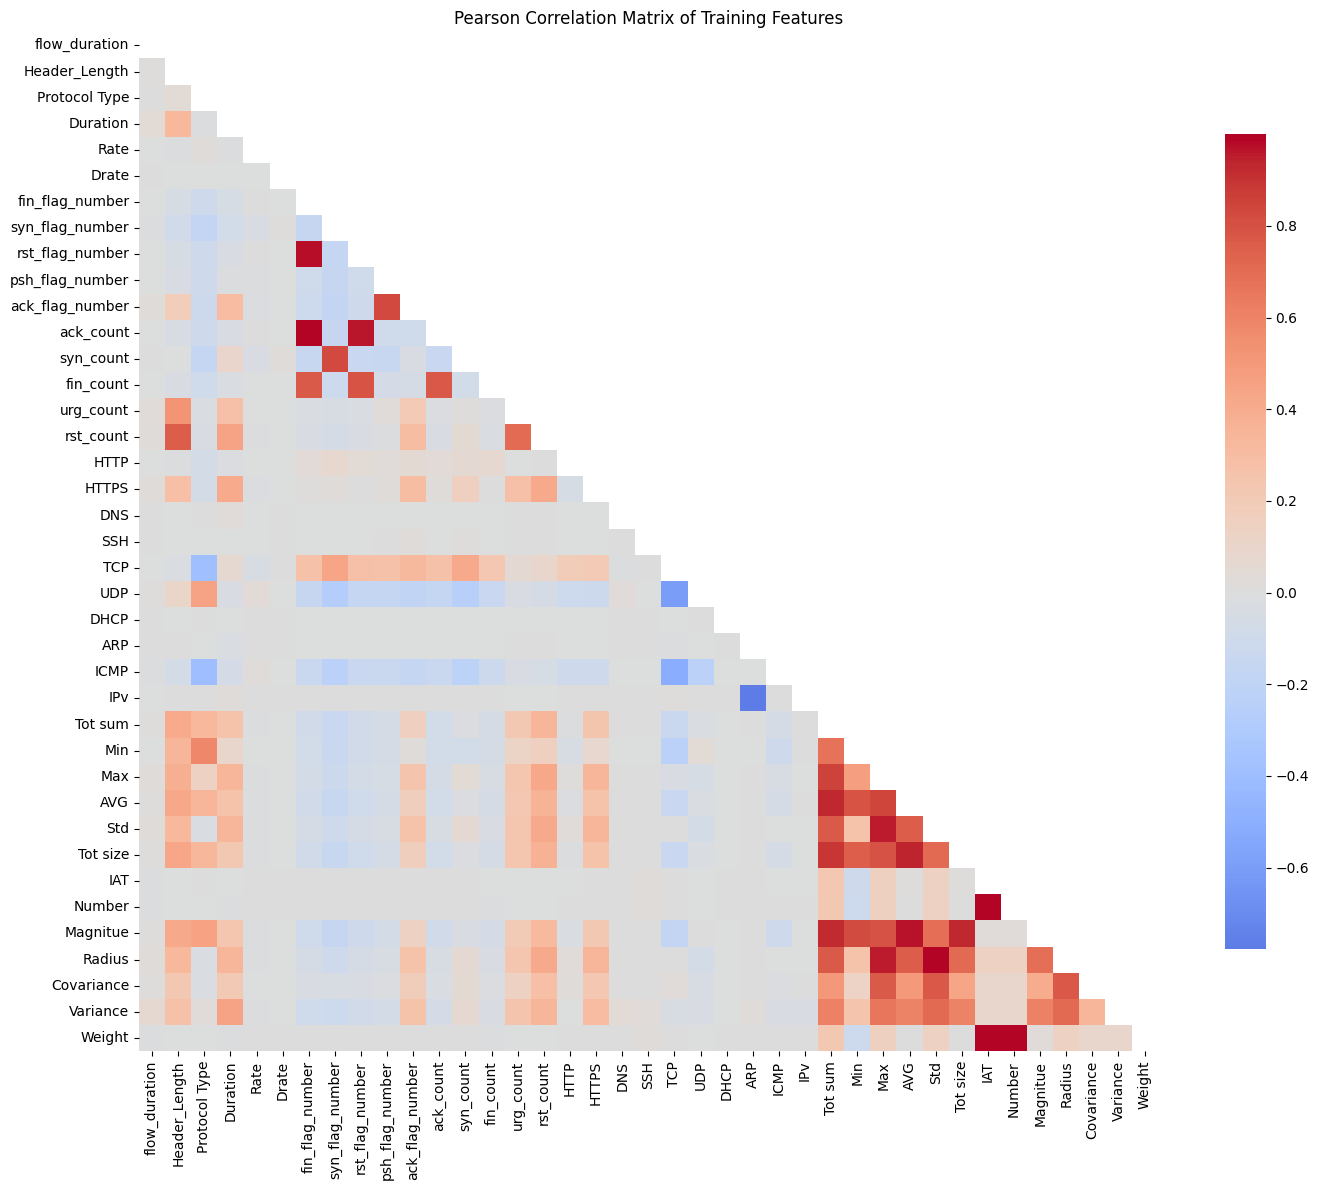


Correlated features removed at |r| >= 0.95 (7):
['rst_flag_number', 'ack_count', 'Std', 'Number', 'Magnitue', 'Radius', 'Weight']

Features before cleaning: 46
Features after cleaning: 32

Cleaned training shape:   (354737, 32)
Cleaned validation shape: (118246, 32)
Cleaned test shape:       (118246, 32)


In [10]:
# ============================================================
# Data-cleaning configuration
# ============================================================
CORRELATION_METHOD = "pearson"
CORRELATION_THRESHOLD = 0.95

original_feature_columns = X_train.columns.tolist()
number_of_features_before_cleaning = len(
    original_feature_columns
)


# ============================================================
# Remove invalid rows independently within each partition
# ============================================================
def remove_invalid_rows_from_partition(
    feature_data,
    target_data,
    row_ids,
    partition_name,
):
    """
    Replace infinite values with NaN and remove incomplete rows
    while preserving target and original-row-ID alignment.
    """
    feature_data = feature_data.replace(
        ["Infinity", "infinity", np.inf, -np.inf],
        np.nan
    )

    target_data = np.asarray(target_data)
    row_ids = np.asarray(row_ids, dtype=np.int64)

    if not (
        len(feature_data)
        == len(target_data)
        == len(row_ids)
    ):
        raise ValueError(
            f"{partition_name}: features, labels, and row IDs "
            "are not aligned."
        )

    valid_row_mask = (
        feature_data.notna().all(axis=1).to_numpy()
    )

    removed_row_ids = row_ids[~valid_row_mask]

    cleaned_features = (
        feature_data.loc[valid_row_mask]
        .reset_index(drop=True)
        .astype(np.float32)
    )

    cleaned_targets = target_data[valid_row_mask]
    cleaned_row_ids = row_ids[valid_row_mask]

    print(f"{partition_name} before cleaning: {feature_data.shape}")
    print(f"{partition_name} after cleaning:  {cleaned_features.shape}")
    print(
        f"{partition_name} rows removed: "
        f"{len(removed_row_ids):,}"
    )

    if cleaned_features.empty:
        raise ValueError(
            f"{partition_name} is empty after invalid-row removal."
        )

    return (
        cleaned_features,
        cleaned_targets,
        cleaned_row_ids,
        removed_row_ids,
    )


(
    X_train,
    y_train,
    row_train,
    invalid_train_row_ids,
) = remove_invalid_rows_from_partition(
    X_train,
    y_train,
    row_train,
    "Training",
)

(
    X_val,
    y_val,
    row_val,
    invalid_val_row_ids,
) = remove_invalid_rows_from_partition(
    X_val,
    y_val,
    row_val,
    "Validation",
)

(
    X_test,
    y_test,
    row_test,
    invalid_test_row_ids,
) = remove_invalid_rows_from_partition(
    X_test,
    y_test,
    row_test,
    "Test",
)


# ============================================================
# Verify compatibility with the subsequent log1p transform
# ============================================================
for partition_name, feature_data in [
    ("Training", X_train),
    ("Validation", X_val),
    ("Test", X_test),
]:
    feature_array = feature_data.to_numpy(
        dtype=np.float32
    )

    if not np.isfinite(feature_array).all():
        raise ValueError(
            f"{partition_name} still contains missing or "
            "infinite values after cleaning."
        )

    if np.any(feature_array <= -1):
        raise ValueError(
            f"{partition_name} contains feature values less "
            "than or equal to -1. The subsequent log1p "
            "transformation requires values greater than -1."
        )


# ============================================================
# Identify constant columns from training data only
# ============================================================
constant_columns = [
    column
    for column in X_train.columns
    if X_train[column].nunique(dropna=False) <= 1
]

X_train = X_train.drop(
    columns=constant_columns
)

X_val = X_val.drop(
    columns=constant_columns
)

X_test = X_test.drop(
    columns=constant_columns
)

print(
    f"\nConstant columns removed "
    f"({len(constant_columns)}):"
)
print(constant_columns)


# ============================================================
# Identify duplicate columns from training data only
# ============================================================
def find_duplicate_columns(feature_data):
    """
    Return columns that exactly duplicate an earlier
    training feature.
    """
    candidate_columns = feature_data.columns.tolist()
    duplicate_columns_found = []

    for index, first_column in enumerate(
        candidate_columns
    ):
        for second_column in candidate_columns[
            index + 1:
        ]:
            if feature_data[first_column].equals(
                feature_data[second_column]
            ):
                duplicate_columns_found.append(
                    second_column
                )

    return sorted(set(duplicate_columns_found))


duplicate_columns = find_duplicate_columns(
    X_train
)

X_train = X_train.drop(
    columns=duplicate_columns
)

X_val = X_val.drop(
    columns=duplicate_columns
)

X_test = X_test.drop(
    columns=duplicate_columns
)

print(
    f"\nDuplicate columns removed "
    f"({len(duplicate_columns)}):"
)
print(duplicate_columns)


# ============================================================
# Calculate correlations using training features only
# ============================================================
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

if not numeric_features:
    raise ValueError(
        "No numeric training features remain for correlation analysis."
    )

correlation_matrix = X_train[
    numeric_features
].corr(
    method=CORRELATION_METHOD
)


# ============================================================
# Plot the training-only correlation matrix
# ============================================================
correlation_mask = np.triu(
    np.ones_like(
        correlation_matrix,
        dtype=bool
    )
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    mask=correlation_mask,
    cmap="coolwarm",
    center=0,
    square=True,
    cbar_kws={"shrink": 0.8},
)

plt.title(
    "Pearson Correlation Matrix of Training Features"
)
plt.tight_layout()
plt.show()


# ============================================================
# Identify correlated columns from training data only
# ============================================================
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(
            correlation_matrix.shape
        ),
        k=1,
    ).astype(bool)
)

correlated_features = [
    column
    for column in upper_triangle.columns
    if (
        upper_triangle[column].abs()
        >= CORRELATION_THRESHOLD
    ).any()
]


# ============================================================
# Apply training-derived feature removal to all partitions
# ============================================================
X_train = X_train.drop(
    columns=correlated_features
)

X_val = X_val.drop(
    columns=correlated_features
)

X_test = X_test.drop(
    columns=correlated_features
)

retained_feature_columns = (
    X_train.columns.tolist()
)


# ============================================================
# Verify identical schemas across all partitions
# ============================================================
if X_val.columns.tolist() != retained_feature_columns:
    raise ValueError(
        "Validation feature schema does not match training."
    )

if X_test.columns.tolist() != retained_feature_columns:
    raise ValueError(
        "Test feature schema does not match training."
    )

if not (
    X_train.shape[1]
    == X_val.shape[1]
    == X_test.shape[1]
):
    raise ValueError(
        "The cleaned partitions have inconsistent feature counts."
    )


print(
    f"\nCorrelated features removed at |r| >= "
    f"{CORRELATION_THRESHOLD} "
    f"({len(correlated_features)}):"
)
print(correlated_features)

print(
    f"\nFeatures before cleaning: "
    f"{number_of_features_before_cleaning}"
)
print(
    f"Features after cleaning: "
    f"{len(retained_feature_columns)}"
)

print(f"\nCleaned training shape:   {X_train.shape}")
print(f"Cleaned validation shape: {X_val.shape}")
print(f"Cleaned test shape:       {X_test.shape}")


## Configure label-independent anomaly-score generation

No multiclass label, binary mask, or label-derived class proportion is used to fit or configure the anomaly-score generators.


In [13]:
# ============================================================
# Confirm the label-independent anomaly-stage configuration
# ============================================================
if not 0 < SUOD_CONTAMINATION <= 0.5:
    raise ValueError(
        "SUOD_CONTAMINATION must be in the interval (0, 0.5]."
    )

print("Isolation Forest contamination: auto")
print(f"SUOD fixed contamination: {SUOD_CONTAMINATION:.2f}")
print("Autoencoder training data: all training observations")
print("Binary anomaly labels: not generated or used")
print("Multiclass labels used by anomaly models: no")


Isolation Forest contamination: auto
SUOD fixed contamination: 0.10
Autoencoder training data: all training observations
Binary anomaly labels: not generated or used
Multiclass labels used by anomaly models: no


## Prepare inputs for anomaly-score generation

In [16]:
# ============================================================
# Apply log transformation separately to each partition
# ============================================================
# log1p is applied before standardization.
X_train_log = np.log1p(
    X_train.to_numpy(dtype=np.float32)
)

X_val_log = np.log1p(
    X_val.to_numpy(dtype=np.float32)
)

X_test_log = np.log1p(
    X_test.to_numpy(dtype=np.float32)
)


# ============================================================
# Fit the anomaly scaler on training data only
# ============================================================
anomaly_scaler = StandardScaler()

X_train_anomaly = anomaly_scaler.fit_transform(
    X_train_log
).astype(np.float32)

X_val_anomaly = anomaly_scaler.transform(
    X_val_log
).astype(np.float32)

X_test_anomaly = anomaly_scaler.transform(
    X_test_log
).astype(np.float32)


print(f"Anomaly training input:   {X_train_anomaly.shape}")
print(f"Anomaly validation input: {X_val_anomaly.shape}")
print(f"Anomaly test input:       {X_test_anomaly.shape}")

Anomaly training input:   (354737, 32)
Anomaly validation input: (118246, 32)
Anomaly test input:       (118246, 32)


## Generate Isolation Forest scores

In [19]:
# ============================================================
# Build and fit Isolation Forest on training features only
# ============================================================
isolation_forest = IsolationForest(
    n_estimators=250,
    contamination="auto",
    max_features=0.75,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

isolation_forest.fit(X_train_anomaly)


# ============================================================
# Generate continuous raw Isolation Forest scores
# ============================================================
# sklearn score_samples direction:
#   Higher value = stronger inlier
#   Lower value  = stronger outlier
#
# score_samples() is used because it is independent of the fitted
# binary decision threshold. No sign reversal is applied.
if_train_scores = isolation_forest.score_samples(X_train_anomaly)
if_val_scores = isolation_forest.score_samples(X_val_anomaly)
if_test_scores = isolation_forest.score_samples(X_test_anomaly)

print("Isolation Forest continuous scores generated successfully.")
print(f"Training scores:   {if_train_scores.shape}")
print(f"Validation scores: {if_val_scores.shape}")
print(f"Test scores:       {if_test_scores.shape}")


Isolation Forest continuous scores generated successfully.
Training scores:   (354737,)
Validation scores: (118246,)
Test scores:       (118246,)


## Define and train the Autoencoder

In [22]:
# ============================================================
# Define the Autoencoder architecture
# ============================================================
def build_autoencoder(input_dimension):
    input_layer = Input(
        shape=(input_dimension,),
        name="input_layer"
    )

    # Encoder
    encoded = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.00001)
    )(input_layer)

    encoded = Dropout(0.20)(encoded)

    encoded = Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.00001)
    )(encoded)

    # Latent representation
    latent = Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.00001),
        name="latent_representation"
    )(encoded)

    # Decoder
    decoded = Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.00001)
    )(latent)

    decoded = Dropout(0.20)(decoded)

    decoded = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.00001)
    )(decoded)

    # Linear output for standardized input features
    output_layer = Dense(
        input_dimension,
        activation="linear",
        name="reconstructed_output"
    )(decoded)

    return Model(
        inputs=input_layer,
        outputs=output_layer,
        name="Autoencoder"
    )


# ============================================================
# Use all training observations for label-independent AE fitting
# ============================================================
# No label-selected class is used in the Autoencoder stage.
X_ae_reference = X_train_anomaly

if len(X_ae_reference) < 2:
    raise ValueError(
        "Insufficient training samples for Autoencoder training."
    )

print(
    f"Autoencoder training observations: "
    f"{len(X_ae_reference):,}"
)


# ============================================================
# Internal split for Autoencoder early stopping
# ============================================================
# Both subsets come exclusively from the training partition.
X_ae_train, X_ae_internal_val = train_test_split(
    X_ae_reference,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True
)


# ============================================================
# Build and compile the Autoencoder
# ============================================================
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

autoencoder = build_autoencoder(
    input_dimension=X_train_anomaly.shape[1]
)

autoencoder.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),
    loss="mse"
)


# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)


# ============================================================
# Train the Autoencoder
# ============================================================
history = autoencoder.fit(
    X_ae_train,
    X_ae_train,
    validation_data=(
        X_ae_internal_val,
        X_ae_internal_val
    ),
    epochs=50,
    batch_size=64,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

Autoencoder training observations: 354,737

Epoch 1/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 19s 4ms/step - loss: 0.5047 - val_loss: 0.2910
Epoch 2/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - loss: 0.3609 - val_loss: 0.2258
Epoch 3/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - loss: 0.3152 - val_loss: 0.1877
Epoch 4/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - loss: 0.2812 - val_loss: 0.1615
Epoch 5/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - loss: 0.2581 - val_loss: 0.1412
Epoch 6/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - loss: 0.2407 - val_loss: 0.1254
Epoch 7/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.2202 - val_loss: 0.1096
Epoch 8/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - loss: 0.2073 - val_loss: 0.1039
Epoch 9/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - loss: 0.1989 - val_loss: 0.0932
Epoch 10/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - loss: 0.1916 - val_loss: 0.0858
Epoch 11/50
4435/4435 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - loss: 0

## Generate Autoencoder reconstruction-error scores

In [24]:
# ============================================================
# Autoencoder anomaly-score function
# ============================================================
def generate_autoencoder_scores(model, X_data):
    reconstructed_data = model.predict(
        X_data,
        batch_size=1024,
        verbose=0
    )

    # Mean squared reconstruction error for every instance
    reconstruction_error = np.mean(
        np.square(X_data - reconstructed_data),
        axis=1
    )

    return reconstruction_error


# ============================================================
# Generate scores for all three partitions
# ============================================================
ae_train_scores = generate_autoencoder_scores(
    autoencoder,
    X_train_anomaly
)

ae_val_scores = generate_autoencoder_scores(
    autoencoder,
    X_val_anomaly
)

ae_test_scores = generate_autoencoder_scores(
    autoencoder,
    X_test_anomaly
)


print("Autoencoder scores generated successfully.")
print(f"Training scores:   {ae_train_scores.shape}")
print(f"Validation scores: {ae_val_scores.shape}")
print(f"Test scores:       {ae_test_scores.shape}")

Autoencoder scores generated successfully.
Training scores:   (354737,)
Validation scores: (118246,)
Test scores:       (118246,)


## Generate SUOD scores

In [26]:
# ============================================================
# Define SUOD base detectors
# ============================================================
# The fixed 0.10 setting is independent of the class labels. PyOD
# uses contamination to construct binary thresholds and labels,
# which are not retained or used in this feature-augmentation study.
suod_base_detectors = [
    IForest(
        n_estimators=100,
        contamination=SUOD_CONTAMINATION,
        random_state=RANDOM_STATE,
    ),
    LOF(
        n_neighbors=20,
        contamination=SUOD_CONTAMINATION,
    ),
    PCA(contamination=SUOD_CONTAMINATION),
    ECOD(contamination=SUOD_CONTAMINATION),
]


# ============================================================
# Build and fit SUOD on training features only
# ============================================================
suod = SUOD(
    base_estimators=suod_base_detectors,
    combination="average",
    contamination=SUOD_CONTAMINATION,
    n_jobs=1,
    verbose=True,
)

suod.fit(X_train_anomaly)


# ============================================================
# Generate continuous SUOD scores
# ============================================================
# PyOD/SUOD score direction:
#   Higher value = stronger outlier
#   Lower value  = stronger inlier
#
# decision_scores_ contains the fitted training scores. Validation
# and test data are scored without refitting the ensemble.
suod_train_scores = np.asarray(
    suod.decision_scores_, dtype=np.float64
)
suod_val_scores = np.asarray(
    suod.decision_function(X_val_anomaly), dtype=np.float64
)
suod_test_scores = np.asarray(
    suod.decision_function(X_test_anomaly), dtype=np.float64
)

print("SUOD continuous scores generated successfully.")
print(f"Training scores:   {suod_train_scores.shape}")
print(f"Validation scores: {suod_val_scores.shape}")
print(f"Test scores:       {suod_test_scores.shape}")


RandomForestRegressor()
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel Training...


  File "C:\Users\zmski\anaconda3\envs\fresh-gpu\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\zmski\anaconda3\envs\fresh-gpu\Lib\subprocess.py", line 550, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\zmski\anaconda3\envs\fresh-gpu\Lib\subprocess.py", line 1028, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\zmski\anaconda3\envs\fresh-gpu\Lib\subprocess.py", line 1540, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Balanced Scheduling Total Train Time: 384.8741064071655
Split among workers default: [4] []
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel score prediction...
Parallel Score Prediction without Approximators Total Time: 13.623917579650879
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel score prediction...
Parallel Score Prediction without Approximators Total Time: 12.979212522506714
SUOD continuous scores generated successfully.
Training scores:   (354737,)
Validation scores: (118246,)
Test scores:       (118246,)


## Save the generated anomaly scores

In [28]:
# ============================================================
# Verify score-to-instance alignment
# ============================================================
assert len(if_train_scores) == len(X_train)
assert len(ae_train_scores) == len(X_train)
assert len(suod_train_scores) == len(X_train)

assert len(if_val_scores) == len(X_val)
assert len(ae_val_scores) == len(X_val)
assert len(suod_val_scores) == len(X_val)

assert len(if_test_scores) == len(X_test)
assert len(ae_test_scores) == len(X_test)
assert len(suod_test_scores) == len(X_test)


# ============================================================
# Create score-only DataFrames
# ============================================================
train_anomaly_scores = pd.DataFrame({
    "IF_Anomaly_Score": if_train_scores,
    "AE_Anomaly_Score": ae_train_scores,
    "SUOD_Anomaly_Score": suod_train_scores
})

val_anomaly_scores = pd.DataFrame({
    "IF_Anomaly_Score": if_val_scores,
    "AE_Anomaly_Score": ae_val_scores,
    "SUOD_Anomaly_Score": suod_val_scores
})

test_anomaly_scores = pd.DataFrame({
    "IF_Anomaly_Score": if_test_scores,
    "AE_Anomaly_Score": ae_test_scores,
    "SUOD_Anomaly_Score": suod_test_scores
})


# ============================================================
# Save score-only CSV files
# ============================================================
train_score_path = (
    OUTPUT_DIRECTORY / "Anomaly_Scores_Train.csv"
)

val_score_path = (
    OUTPUT_DIRECTORY / "Anomaly_Scores_Validation.csv"
)

test_score_path = (
    OUTPUT_DIRECTORY / "Anomaly_Scores_Test.csv"
)

train_anomaly_scores.to_csv(
    train_score_path,
    index=False
)

val_anomaly_scores.to_csv(
    val_score_path,
    index=False
)

test_anomaly_scores.to_csv(
    test_score_path,
    index=False
)


# print(f"Training scores saved to: {train_score_path}")
# print(f"Validation scores saved to: {val_score_path}")
# print(f"Test scores saved to: {test_score_path}")

display(train_anomaly_scores.head())

,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score
0,-0.383167,0.006203,-0.277339
1,-0.375013,0.003702,-0.291433
2,-0.497323,0.039364,0.648249
3,-0.339044,0.001382,-0.766263
4,-0.441385,0.012947,0.238320


## Augment and save the original feature partitions

In [37]:
# ============================================================
# Augment the original unscaled training features
# ============================================================
X_train_augmented = X_train.copy()

X_train_augmented["IF_Anomaly_Score"] = (
    if_train_scores
)

X_train_augmented["AE_Anomaly_Score"] = (
    ae_train_scores
)

X_train_augmented["SUOD_Anomaly_Score"] = (
    suod_train_scores
)


# ============================================================
# Augment the original unscaled validation features
# ============================================================
X_val_augmented = X_val.copy()

X_val_augmented["IF_Anomaly_Score"] = (
    if_val_scores
)

X_val_augmented["AE_Anomaly_Score"] = (
    ae_val_scores
)

X_val_augmented["SUOD_Anomaly_Score"] = (
    suod_val_scores
)


# ============================================================
# Augment the original unscaled test features
# ============================================================
X_test_augmented = X_test.copy()

X_test_augmented["IF_Anomaly_Score"] = (
    if_test_scores
)

X_test_augmented["AE_Anomaly_Score"] = (
    ae_test_scores
)

X_test_augmented["SUOD_Anomaly_Score"] = (
    suod_test_scores
)


# Verify that exactly three features were added
expected_feature_count = X_train.shape[1] + 3

assert X_train_augmented.shape[1] == expected_feature_count
assert X_val_augmented.shape[1] == expected_feature_count
assert X_test_augmented.shape[1] == expected_feature_count


# ============================================================
# Add original multiclass labels as the final column
# ============================================================
train_augmented_output = X_train_augmented.copy()
val_augmented_output = X_val_augmented.copy()
test_augmented_output = X_test_augmented.copy()

train_augmented_output[LABEL_COLUMN] = (
    label_encoder.inverse_transform(y_train)
)

val_augmented_output[LABEL_COLUMN] = (
    label_encoder.inverse_transform(y_val)
)

test_augmented_output[LABEL_COLUMN] = (
    label_encoder.inverse_transform(y_test)
)


# ============================================================
# Save augmented partitions for classifier training and evaluation
# ============================================================
train_augmented_path = (
    OUTPUT_DIRECTORY / "CICIoT2023_Augmented_Train.csv"
)

val_augmented_path = (
    OUTPUT_DIRECTORY / "CICIoT2023_Augmented_Validation.csv"
)

test_augmented_path = (
    OUTPUT_DIRECTORY / "CICIoT2023_Augmented_Test.csv"
)

train_augmented_output.to_csv(
    train_augmented_path,
    index=False
)

val_augmented_output.to_csv(
    val_augmented_path,
    index=False
)

test_augmented_output.to_csv(
    test_augmented_path,
    index=False
)


# print(f"Original feature count: {X_train.shape[1]}")
# print(f"Augmented feature count: {expected_feature_count}")

# print(f"\nTraining dataset saved to: {train_augmented_path}")
# print(f"Validation dataset saved to: {val_augmented_path}")
# print(f"Test dataset saved to: {test_augmented_path}")

display(train_augmented_output.head())

# ============================================================
# Save the exact split assignment for independent reproduction
# ============================================================
# This manifest contains metadata only and is not used as a model input.
split_manifest = pd.concat(
    [
        pd.DataFrame({
            "Original_Row_ID": row_train,
            "Data_Split": "Train",
            LABEL_COLUMN: label_encoder.inverse_transform(y_train),
        }),
        pd.DataFrame({
            "Original_Row_ID": row_val,
            "Data_Split": "Validation",
            LABEL_COLUMN: label_encoder.inverse_transform(y_val),
        }),
        pd.DataFrame({
            "Original_Row_ID": row_test,
            "Data_Split": "Test",
            LABEL_COLUMN: label_encoder.inverse_transform(y_test),
        }),
    ],
    ignore_index=True,
).sort_values("Original_Row_ID").reset_index(drop=True)

split_manifest_path = OUTPUT_DIRECTORY / "CICIoT2023_Split_Manifest.csv"
split_manifest.to_csv(split_manifest_path, index=False)
# print(f"Split manifest saved to: {split_manifest_path}")


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.000000,3202.228516,0.0,0.0,0.0,0.0,0.0,...,50.00,50.000000,50.00,83102416.0,0.000000,0.00,-0.383167,0.006203,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.000000,8785.439453,0.0,0.0,0.0,0.0,0.0,...,50.00,50.000000,50.00,83123744.0,0.000000,0.00,-0.375013,0.003702,-0.291433,DDoS
2,0.000000,0.0,47.00,64.000000,218.863708,0.0,0.0,0.0,0.0,0.0,...,592.00,592.000000,592.00,83698552.0,0.000000,0.00,-0.497323,0.039364,0.648249,Mirai
3,0.000000,54.0,6.00,64.000000,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.000000,54.00,83064136.0,0.000000,0.00,-0.339044,0.001382,-0.766263,DDoS
4,0.000000,0.0,0.99,63.360001,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.138378,42.18,83150648.0,2.315749,0.11,-0.441385,0.012947,0.238320,DDoS


### Save Anomaly Score Generator Models 

In [50]:
import json
import joblib

from tensorflow.keras.models import load_model

In [52]:
# ============================================================
# Directory and paths for saved anomaly-generation artifacts
# ============================================================
ANOMALY_MODEL_DIRECTORY = OUTPUT_DIRECTORY / "saved_anomaly_models"
ANOMALY_MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)

ANOMALY_SCALER_PATH = ANOMALY_MODEL_DIRECTORY / "anomaly_scaler.joblib"
ISOLATION_FOREST_PATH = ANOMALY_MODEL_DIRECTORY / "isolation_forest.joblib"
AUTOENCODER_PATH = ANOMALY_MODEL_DIRECTORY / "autoencoder.keras"
SUOD_PATH = ANOMALY_MODEL_DIRECTORY / "suod.joblib"
LABEL_ENCODER_PATH = ANOMALY_MODEL_DIRECTORY / "label_encoder.joblib"
METADATA_PATH = ANOMALY_MODEL_DIRECTORY / "anomaly_model_metadata.json"
ANOMALY_TEST_INPUT_PATH = ANOMALY_MODEL_DIRECTORY / "X_test_anomaly.npy"


# ============================================================
# Save fitted preprocessing components and anomaly models
# ============================================================
joblib.dump(anomaly_scaler, ANOMALY_SCALER_PATH)
joblib.dump(label_encoder, LABEL_ENCODER_PATH)
joblib.dump(isolation_forest, ISOLATION_FOREST_PATH)
autoencoder.save(AUTOENCODER_PATH)
joblib.dump(suod, SUOD_PATH)

# Save the exact preprocessed test matrix used for feature-generation timing.
# This allows the timing experiment to be repeated later without refitting
# the anomaly scaler or retraining any anomaly detector.
np.save(
    ANOMALY_TEST_INPUT_PATH,
    X_test_anomaly.astype(np.float32),
)


# ============================================================
# Save feature schema, split settings, and model metadata
# ============================================================
anomaly_metadata = {
    "feature_columns": retained_feature_columns,
    "label_column": LABEL_COLUMN,
    "random_state": int(RANDOM_STATE),
    "split": {
        "first_test_size": 0.40,
        "second_test_size": 0.50,
        "final_proportions": {
            "train": 0.60,
            "validation": 0.20,
            "test": 0.20,
        },
        "stratified_on": "original multiclass label",
        "manifest": "CICIoT2023_Split_Manifest.csv",
    },
    "number_of_original_features": int(X.shape[1]),
    "number_of_retained_features": int(X_train.shape[1]),
    "data_cleaning": {
        "invalid_row_rule": (
            "replace infinite values with NaN and remove "
            "incomplete rows independently within each partition"
        ),
        "invalid_training_rows_removed": int(
            len(invalid_train_row_ids)
        ),
        "invalid_validation_rows_removed": int(
            len(invalid_val_row_ids)
        ),
        "invalid_test_rows_removed": int(
            len(invalid_test_row_ids)
        ),
        "constant_columns": constant_columns,
        "duplicate_columns": duplicate_columns,
        "correlation_method": CORRELATION_METHOD,
        "correlation_threshold": float(
            CORRELATION_THRESHOLD
        ),
        "correlated_columns": correlated_features,
        "feature_selection_source": "training partition only",
    },
    "anomaly_training_policy": (
        "label-independent; preprocessing and all anomaly models "
        "were fitted on training features only"
    ),
    "isolation_forest": {
        "contamination": "auto",
        "score_method": "score_samples",
        "binary_predictions_used": False,
    },
    "autoencoder": {
        "training_data": "all training observations",
        "score_method": "per-row reconstruction MSE",
        "binary_threshold_used": False,
    },
    "suod": {
        "contamination": float(SUOD_CONTAMINATION),
        "contamination_source": "fixed a priori; independent of labels",
        "binary_predictions_used": False,
        "score_method": "decision_scores_/decision_function",
    },
    "preprocessing": {
        "log_transformation": "numpy.log1p",
        "scaling": "StandardScaler fitted on training data",
    },
    "score_columns": [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ],
    "score_directions": {
        "IF_Anomaly_Score": "lower value indicates stronger outlier",
        "AE_Anomaly_Score": "higher value indicates stronger outlier",
        "SUOD_Anomaly_Score": "higher value indicates stronger outlier",
    },
    "feature_generation_timing": {
        "definition": (
            "time required by the saved IForest, AE, and SUOD models "
            "to generate the three anomaly-score features"
        ),
        "preprocessing_included": False,
        "model_loading_included": False,
        "training_included": False,
        "benchmark_input": "X_test_anomaly.npy",
        "warmup_runs": 3,
        "timed_runs": 5,
        "repetition_file": "Anomaly_Feature_Generation_Timing_Repetitions.csv",
        "summary_file": "Anomaly_Feature_Generation_Timing_Summary.csv",
        "protocol_file": "Anomaly_Feature_Generation_Timing_Protocol.json",
    },
}

with open(METADATA_PATH, "w", encoding="utf-8") as metadata_file:
    json.dump(anomaly_metadata, metadata_file, indent=4)

print("Anomaly-generation artifacts saved successfully:\n")
# print(f"Scaler:           {ANOMALY_SCALER_PATH}")
# print(f"Isolation Forest: {ISOLATION_FOREST_PATH}")
# print(f"Autoencoder:      {AUTOENCODER_PATH}")
# print(f"SUOD:             {SUOD_PATH}")
# print(f"Label encoder:    {LABEL_ENCODER_PATH}")
# print(f"Metadata:         {METADATA_PATH}")
# print(f"Exact timing input: {ANOMALY_TEST_INPUT_PATH}")


Anomaly-generation artifacts saved successfully:



### Feature-Generation Timing using the saved anomaly models

This benchmark measures only the time required by the pre-trained IForest, Autoencoder, and SUOD models to generate the three anomaly-score features. Model fitting, model loading, and anomaly-stage preprocessing are excluded. Three warm-up runs are discarded and five full-test repetitions are timed.


### Part 2: Final 

In [21]:
# ============================================================
# Offline anomaly feature-generation timing
# ============================================================
# Reproduces anomaly-score feature generation without retraining.
#
# Timing definition:
# - saved fitted IForest, AE, and SUOD models,
# - preprocessing excluded,
# - model loading excluded,
# - model fitting/training excluded,
# - 3 full-test warm-up runs,
# - 5 timed full-test repetitions,
# - AE inference batch size = 256.
# ============================================================

import time
import json
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display


# ============================================================
# Paths
# ============================================================
OUTPUT_DIRECTORY = Path(  
    r"\Outputs_CICIoT2023_Final"
)

ANOMALY_MODEL_DIRECTORY = (
    OUTPUT_DIRECTORY
    / "saved_anomaly_models"
)

ISOLATION_FOREST_PATH = (
    ANOMALY_MODEL_DIRECTORY
    / "isolation_forest.joblib"
)

AUTOENCODER_PATH = (
    ANOMALY_MODEL_DIRECTORY
    / "autoencoder.keras"
)

SUOD_PATH = (
    ANOMALY_MODEL_DIRECTORY
    / "suod.joblib"
)

# IMPORTANT:
# This must point to the .npy FILE, not the folder.
ANOMALY_TEST_INPUT_PATH = (
    ANOMALY_MODEL_DIRECTORY
    / "X_test_anomaly.npy"
)


# ============================================================
# Timing protocol
# ============================================================
N_TIMING_WARMUP_RUNS = 3
N_TIMING_RUNS = 5

# Same neural-network inference batch size used for
# classifier inference measurements.
INFERENCE_BATCH_SIZE = 256


# ============================================================
# Validate required saved artifacts
# ============================================================
required_files = {
    "Isolation Forest":
        ISOLATION_FOREST_PATH,

    "Autoencoder":
        AUTOENCODER_PATH,

    "SUOD":
        SUOD_PATH,

    "Anomaly test input":
        ANOMALY_TEST_INPUT_PATH,
}

for artifact_name, artifact_path in required_files.items():

    if not artifact_path.is_file():

        raise FileNotFoundError(
            f"{artifact_name} not found:\n"
            f"{artifact_path}"
        )


# ============================================================
# Load saved models
# Model loading is OUTSIDE the timed region
# ============================================================
isolation_forest_loaded = joblib.load(
    ISOLATION_FOREST_PATH
)

autoencoder_loaded = (
    tf.keras.models.load_model(
        AUTOENCODER_PATH,
        compile=False,
    )
)

suod_loaded = joblib.load(
    SUOD_PATH
)


# ============================================================
# Load exact preprocessed anomaly-model test input
# ============================================================
X_test_anomaly_timing = np.load(
    ANOMALY_TEST_INPUT_PATH
).astype(
    np.float32
)

N_TEST_SAMPLES = len(
    X_test_anomaly_timing
)

if N_TEST_SAMPLES == 0:

    raise ValueError(
        "The saved anomaly test tensor contains no samples."
    )

if not np.isfinite(
    X_test_anomaly_timing
).all():

    raise ValueError(
        "The saved anomaly test tensor contains "
        "NaN or infinite values."
    )


print(
    "Saved anomaly models loaded successfully."
)

print(
    f"Timing input: {ANOMALY_TEST_INPUT_PATH}"
)

print(
    f"Test tensor shape: "
    f"{X_test_anomaly_timing.shape}"
)

print(
    f"Test samples: {N_TEST_SAMPLES:,}"
)


# ============================================================
# 3 untimed FULL-test warm-up runs
# ============================================================
for _ in range(
    N_TIMING_WARMUP_RUNS
):

    # --------------------------------------------------------
    # Isolation Forest
    # --------------------------------------------------------
    _ = isolation_forest_loaded.score_samples(
        X_test_anomaly_timing
    )


    # --------------------------------------------------------
    # Autoencoder
    # --------------------------------------------------------
    ae_reconstruction = (
        autoencoder_loaded.predict(
            X_test_anomaly_timing,
            batch_size=INFERENCE_BATCH_SIZE,
            verbose=0,
        )
    )

    _ = np.mean(
        np.square(
            X_test_anomaly_timing
            - ae_reconstruction
        ),
        axis=1,
    )


    # --------------------------------------------------------
    # SUOD
    # --------------------------------------------------------
    _ = suod_loaded.decision_function(
        X_test_anomaly_timing
    )


# ============================================================
# 5 timed FULL-test repetitions
# ============================================================
timing_records = []


for timing_run in range(
    1,
    N_TIMING_RUNS + 1,
):

    total_start = time.perf_counter()


    # --------------------------------------------------------
    # Isolation Forest anomaly-score generation
    # --------------------------------------------------------
    if_start = time.perf_counter()

    if_scores_timing = (
        isolation_forest_loaded.score_samples(
            X_test_anomaly_timing
        )
    )

    if_time_s = (
        time.perf_counter()
        - if_start
    )


    # --------------------------------------------------------
    # Autoencoder reconstruction-score generation
    # --------------------------------------------------------
    ae_start = time.perf_counter()

    ae_reconstruction = (
        autoencoder_loaded.predict(
            X_test_anomaly_timing,
            batch_size=INFERENCE_BATCH_SIZE,
            verbose=0,
        )
    )

    ae_scores_timing = np.mean(
        np.square(
            X_test_anomaly_timing
            - ae_reconstruction
        ),
        axis=1,
    )

    ae_time_s = (
        time.perf_counter()
        - ae_start
    )


    # --------------------------------------------------------
    # SUOD anomaly-score generation
    # --------------------------------------------------------
    suod_start = time.perf_counter()

    suod_scores_timing = (
        suod_loaded.decision_function(
            X_test_anomaly_timing
        )
    )

    suod_time_s = (
        time.perf_counter()
        - suod_start
    )


    # --------------------------------------------------------
    # Complete feature-generation wall-clock time
    # --------------------------------------------------------
    total_feature_generation_time_s = (
        time.perf_counter()
        - total_start
    )


    # --------------------------------------------------------
    # Latency
    # --------------------------------------------------------
    if_latency_ms = (
        if_time_s
        / N_TEST_SAMPLES
        * 1000.0
    )

    ae_latency_ms = (
        ae_time_s
        / N_TEST_SAMPLES
        * 1000.0
    )

    suod_latency_ms = (
        suod_time_s
        / N_TEST_SAMPLES
        * 1000.0
    )

    total_latency_ms = (
        total_feature_generation_time_s
        / N_TEST_SAMPLES
        * 1000.0
    )


    # --------------------------------------------------------
    # Throughput
    # --------------------------------------------------------
    if_throughput = (
        N_TEST_SAMPLES
        / if_time_s
    )

    ae_throughput = (
        N_TEST_SAMPLES
        / ae_time_s
    )

    suod_throughput = (
        N_TEST_SAMPLES
        / suod_time_s
    )

    total_throughput = (
        N_TEST_SAMPLES
        / total_feature_generation_time_s
    )


    timing_records.append(
        {
            "Run":
                timing_run,

            "IForest_Time_s":
                if_time_s,

            "AE_Time_s":
                ae_time_s,

            "SUOD_Time_s":
                suod_time_s,

            "Total_Feature_Generation_Time_s":
                total_feature_generation_time_s,

            "IForest_ms_per_sample":
                if_latency_ms,

            "AE_ms_per_sample":
                ae_latency_ms,

            "SUOD_ms_per_sample":
                suod_latency_ms,

            "Total_Feature_Generation_ms_per_sample":
                total_latency_ms,

            "IForest_Throughput_samples_per_s":
                if_throughput,

            "AE_Throughput_samples_per_s":
                ae_throughput,

            "SUOD_Throughput_samples_per_s":
                suod_throughput,

            "Feature_Generation_Throughput_samples_per_s":
                total_throughput,
        }
    )


# ============================================================
# Save all five repetition-level measurements
# ============================================================
feature_timing_df = pd.DataFrame(
    timing_records
)

FEATURE_TIMING_REPETITIONS_PATH = (
    OUTPUT_DIRECTORY
    / "Anomaly_Feature_Generation_Timing_Repetitions.csv"
)

feature_timing_df.to_csv(
    FEATURE_TIMING_REPETITIONS_PATH,
    index=False,
)


# ============================================================
# Mean ± sample SD across five technical repetitions
# ============================================================
component_columns = {

    "IForest": {
        "time":
            "IForest_Time_s",

        "latency":
            "IForest_ms_per_sample",

        "throughput":
            "IForest_Throughput_samples_per_s",
    },

    "AE": {
        "time":
            "AE_Time_s",

        "latency":
            "AE_ms_per_sample",

        "throughput":
            "AE_Throughput_samples_per_s",
    },

    "SUOD": {
        "time":
            "SUOD_Time_s",

        "latency":
            "SUOD_ms_per_sample",

        "throughput":
            "SUOD_Throughput_samples_per_s",
    },

    "Total feature generation": {
        "time":
            "Total_Feature_Generation_Time_s",

        "latency":
            "Total_Feature_Generation_ms_per_sample",

        "throughput":
            "Feature_Generation_Throughput_samples_per_s",
    },
}


summary_rows = []


for component, columns in component_columns.items():

    summary_rows.append(
        {
            "Component":
                component,

            "Mean_Time_s":
                feature_timing_df[
                    columns["time"]
                ].mean(),

            "SD_Time_s":
                feature_timing_df[
                    columns["time"]
                ].std(
                    ddof=1
                ),

            "Mean_ms_per_sample":
                feature_timing_df[
                    columns["latency"]
                ].mean(),

            "SD_ms_per_sample":
                feature_timing_df[
                    columns["latency"]
                ].std(
                    ddof=1
                ),

            "Mean_Throughput_samples_per_s":
                feature_timing_df[
                    columns["throughput"]
                ].mean(),

            "SD_Throughput_samples_per_s":
                feature_timing_df[
                    columns["throughput"]
                ].std(
                    ddof=1
                ),
        }
    )


feature_timing_summary_df = pd.DataFrame(
    summary_rows
)


FEATURE_TIMING_SUMMARY_PATH = (
    OUTPUT_DIRECTORY
    / "Anomaly_Feature_Generation_Timing_Summary.csv"
)

feature_timing_summary_df.to_csv(
    FEATURE_TIMING_SUMMARY_PATH,
    index=False,
)


# ============================================================
# Save timing protocol
# ============================================================
FEATURE_TIMING_PROTOCOL_PATH = (
    OUTPUT_DIRECTORY
    / "Anomaly_Feature_Generation_Timing_Protocol.json"
)


feature_timing_protocol = {

    "metric_name":
        "Feature-generation time",

    "definition":
        (
            "Wall-clock time required by the saved fitted "
            "IForest, AE, and SUOD models to generate the "
            "three anomaly-score features."
        ),

    "benchmark_partition":
        "fixed CICIoT2023 test partition",

    "number_of_test_samples":
        int(
            N_TEST_SAMPLES
        ),

    "warmup_runs":
        int(
            N_TIMING_WARMUP_RUNS
        ),

    "timed_runs":
        int(
            N_TIMING_RUNS
        ),

    "ae_inference_batch_size":
        int(
            INFERENCE_BATCH_SIZE
        ),

    "timer":
        "time.perf_counter",

    "preprocessing_included":
        False,

    "model_loading_included":
        False,

    "model_training_included":
        False,

    "autoencoder_score_definition":
        (
            "Autoencoder forward reconstruction followed "
            "by per-sample reconstruction MSE."
        ),

    "benchmark_input":
        str(
            ANOMALY_TEST_INPUT_PATH
        ),

    "reported_statistics":
        (
            "Mean and sample SD (ddof=1) across five "
            "timed full-test repetitions."
        ),
}


with open(
    FEATURE_TIMING_PROTOCOL_PATH,
    "w",
    encoding="utf-8",
) as protocol_file:

    json.dump(
        feature_timing_protocol,
        protocol_file,
        indent=4,
    )


# ============================================================
# Display results
# ============================================================
print(
    "\nFeature-generation timing completed."
)

print(
    f"AE inference batch size: "
    f"{INFERENCE_BATCH_SIZE}"
)

print(
    f"Repetitions saved to:\n"
    f"{FEATURE_TIMING_REPETITIONS_PATH}"
)

print(
    f"Summary saved to:\n"
    f"{FEATURE_TIMING_SUMMARY_PATH}"
)

print(
    f"Protocol saved to:\n"
    f"{FEATURE_TIMING_PROTOCOL_PATH}"
)

display(
    feature_timing_summary_df
)

Saved anomaly models loaded successfully.
Timing input: C:\Users\zmski\Documents\PhdDocuments\Review1_CICIoT2023\Major_Review_V1\AnomalyScoreGenerationUsing_IF_AE_SUDO_CICIoT2023\Outputs_CICIoT2023_Final\saved_anomaly_models\X_test_anomaly.npy
Test tensor shape: (118246, 32)
Test samples: 118,246
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel score prediction...
Parallel Score Prediction without Approximators Total Time: 10.86898946762085
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel score prediction...
Parallel Score Prediction without Approximators Total Time: 11.689016819000244
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel score prediction...
Parallel Score Prediction without Approximators Total Time: 12.478099822998047
Worker 1 sum of ranks: 6.5

Split among workers BPS: [0, 4, 4] [4, 0]
Parallel score prediction...
Parallel Score Prediction without Approximators Total Time: 11.0940587

,Component,Mean_Time_s,SD_Time_s,Mean_ms_per_sample,SD_ms_per_sample,Mean_Throughput_samples_per_s,SD_Throughput_samples_per_s
0,IForest,3.159358,0.143307,0.026719,0.001212,37488.429097,1687.376266
1,AE,1.210626,0.213469,0.010238,0.001805,100015.880815,16610.258941
2,SUOD,14.966196,0.237340,0.126568,0.002007,7902.455491,124.806404
3,Total feature generation,19.336187,0.182962,0.163525,0.001547,6115.709056,58.022162


## End of anomaly-score pipeline 

### Next Step: Train and evaluate the classifier using the cleaned dataset created in this phase.